# Q1 Maize Yield Preparation

This notebook contains the complete workflow. Each stage begins with an explanation before its code. Run the stages from top to bottom in a clean kernel.

## Step 1 — Verify the environment

The explanation below describes this step before the code runs.

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q1 | Stage: 1: environment test

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import platform, pandas as pd, numpy as np, sklearn, joblib
print('Python:', platform.python_version())
print('pandas:', pd.__version__, 'numpy:', np.__version__, 'scikit-learn:', sklearn.__version__, 'joblib:', joblib.__version__)


Python: 3.14.6
pandas: 3.0.3 numpy: 2.4.6 scikit-learn: 1.9.0 joblib: 1.5.3


## Step 2 — Acquire and document the revised dataset

The explanation below describes this step before the code runs.

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q1 | Stage: 2: requirements and acquisition

This notebook documents the revised Rwanda maize source. The raw file is preserved unchanged; the cleaning stage derives model fields and converts tonnes/ha to kg/ha.

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import pandas as pd
from src.config import RAW_FILE, DOCS_DIR, COLUMNS
from src.cleaning import sha256_file, to_string_df

DOCS_DIR.mkdir(parents=True, exist_ok=True)
if not RAW_FILE.exists():
    raise FileNotFoundError(f'Revised Q1 raw file not found: {RAW_FILE}')
df_raw = to_string_df(RAW_FILE)
print('Using file:', RAW_FILE)
print('SHA-256:', sha256_file(RAW_FILE))
print('shape:', df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes.rename('dtype').to_frame())

meta = {
 'record_id': ('Observation identifier','string','unique record code','No'),
 'year': ('Observation year','integer','2015-2030','No'),
 'season': ('Cropping season','category','A/B/C','No'),
 'province': ('Province','category','Rwanda province','No'),
 'district': ('District','category','Rwanda district','No'),
 'altitude_m': ('Altitude','numeric','metres','No'),
 'rainfall_mm': ('Rainfall','numeric','millimetres','No'),
 'avg_temp_c': ('Average temperature','numeric','degrees Celsius','No'),
 'soil_ph': ('Soil acidity','numeric','pH','No'),
 'soil_type': ('Soil category','category','soil class','No'),
 'seed_variety': ('Seed variety','category','variety label','No'),
 'farming_practice': ('Farming practice','category','Traditional/Improved','No'),
 'npk_kg_ha': ('NPK fertiliser','numeric','kg/ha','No'),
 'urea_kg_ha': ('Urea fertiliser','numeric','kg/ha','No'),
 'manure_t_ha': ('Manure','numeric','tonnes/ha','No'),
 'plant_density_per_ha': ('Plant density','numeric','plants/ha','No'),
 'farm_area_ha': ('Farm area','numeric','hectares','No'),
 'irrigation': ('Irrigation','category','Yes/No','No'),
 'pest_incidence_index': ('Pest incidence index','numeric','0-1 index','No'),
 'yield_t_ha': ('Yield target','numeric','tonnes/ha; converted to kg/ha','Yes'),
}
dd = pd.DataFrame([{'column_name': c, 'meaning': meta.get(c, ('','','',''))[0],
                    'data_type': meta.get(c, ('','','',''))[1],
                    'unit': meta.get(c, ('','','',''))[2],
                    'post_harvest_or_target': meta.get(c, ('','','',''))[3]} for c in COLUMNS])
dd.to_csv(DOCS_DIR / 'data_dictionary.csv', index=False)
(DOCS_DIR / 'data_dictionary.md').write_text('# Q1 Data Dictionary\n\n' + dd.to_string(index=False))
(DOCS_DIR / 'data_requirements.md').write_text('''# Q1 Data Requirements

- Target: `yield_t_ha`, converted to `yield_kg_per_ha` for modelling.
- Pre-harvest predictors: weather, altitude, soil, seed, farming practice, fertiliser, density, area, irrigation and pest index.
- The revised file has no harvest-weight column; therefore no post-harvest harvest measure is used as a feature.
- The derived `low_yield_risk` label is created after the train split and excluded from model inputs.
- The source contains 1,426 records and 20 columns, with missing rainfall, soil pH and pest-index values handled during preprocessing.
''')
(DOCS_DIR / 'source_log.md').write_text(f'''# Source Log

- File used: `{RAW_FILE.name}`
- SHA-256: `{sha256_file(RAW_FILE)}`
- Date accessed: {date.today().isoformat()}
- Source description: Rwanda maize yield records supplied for the revised Q1 dataset.
- Limitation: provenance and licence details should be completed from the dataset provider before submission.
''')


Using file: /home/songa/Documents/CODING/CLASS WORK/ML-Learning/q1_maize_yield/data/raw/maize_yield_rwanda_rw.csv
SHA-256: 2a81e0267334b477b740093859e1d0d0555996035b3169672ce774278b620576
shape: (1426, 20)


,record_id,year,season,province,district,altitude_m,rainfall_mm,avg_temp_c,soil_ph,soil_type,seed_variety,farming_practice,npk_kg_ha,urea_kg_ha,manure_t_ha,plant_density_per_ha,farm_area_ha,irrigation,pest_incidence_index,yield_t_ha
0,RW-MZ-00001,2015,A,Eastern,Bugesera,1349,,22.9,,Clay,RHM104,Improved,117.8,57.4,1.41,61803,0.63,No,,2.71
1,RW-MZ-00002,2015,A,Eastern,Bugesera,1427,489.8,22.1,6.02,Volcanic,RHM104,Improved,38.1,62.7,3.69,52919,0.17,No,0.339,4.09
2,RW-MZ-00003,2015,A,Northern,Burera,2033,722.6,16.3,5.73,Clay loam,Local,Improved,121.1,50.7,5.18,54406,0.22,No,0.049,2.58
3,RW-MZ-00004,2015,A,Northern,Burera,2026,794.4,16.4,5.2,Clay loam,ZM621,Improved,93.7,60.4,1.68,48119,0.48,No,0.171,2.45
4,RW-MZ-00005,2015,A,Northern,Gakenke,1974,644.2,18.3,5.92,Loam,Local,Improved,84.1,70.4,0.36,56787,1.16,No,0.001,2.09


,dtype
record_id,str
year,str
season,str
province,str
district,str
altitude_m,str
rainfall_mm,str
avg_temp_c,str
soil_ph,str
soil_type,str


357

## Step 3 — Explore and audit data quality

The explanation below describes this step before the code runs.

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q1 | Stage: 3: EDA and data audit

This notebook audits the revised schema without modifying the raw file, quantifies missingness and duplicates, and creates concise quality charts.

,problem,columns_affected,records_affected,severity,proposed_treatment
0,Exact duplicate rows,all,0,High,Remove exact duplicates
1,Repeated record identifiers,record_id,0,High,Keep the most complete record
2,Missing values,"rainfall_mm,soil_ph,pest_incidence_index",39,Medium,Fit training-only imputers
3,Invalid target or area,"yield_t_ha,farm_area_ha",0,High,Set invalid values missing and drop missing ta...
4,Out-of-range pest index,pest_incidence_index,0,Medium,Set invalid values missing
5,Potential target leakage,yield_t_ha,1426,High,Keep only as target; never include it in X


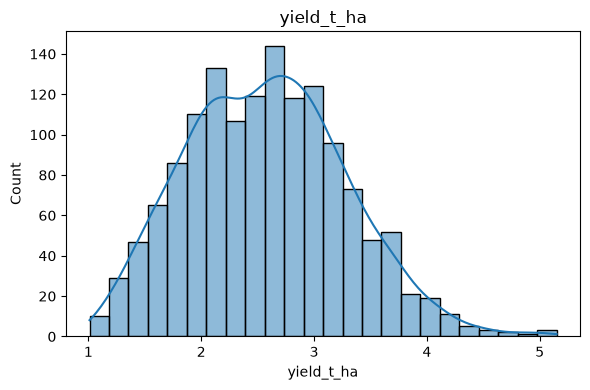

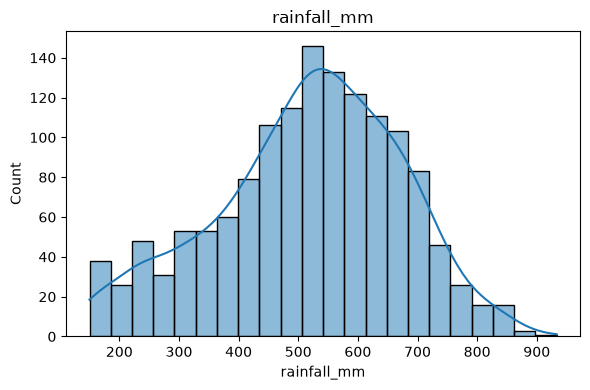

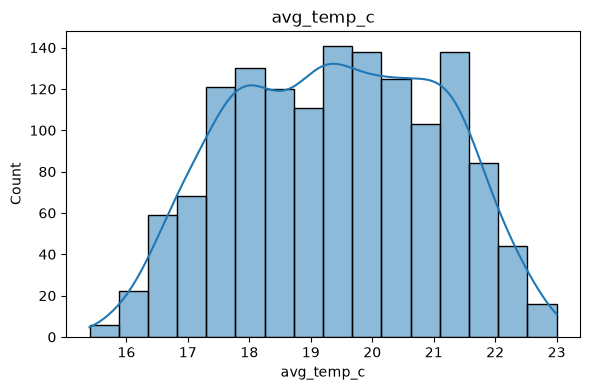

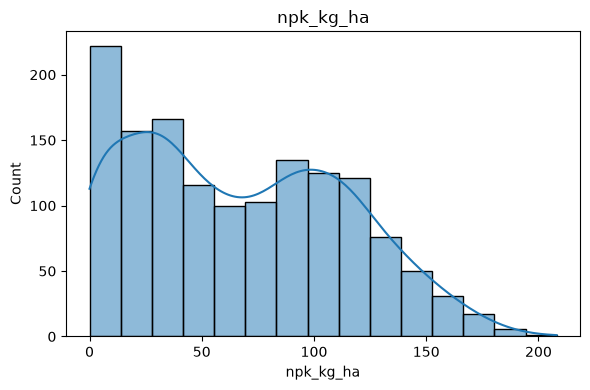

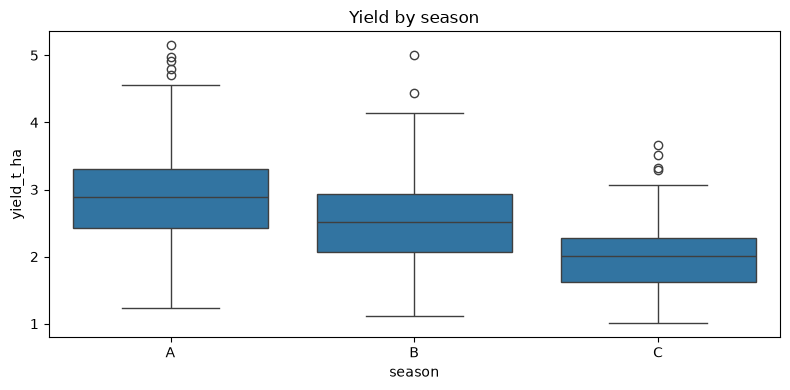

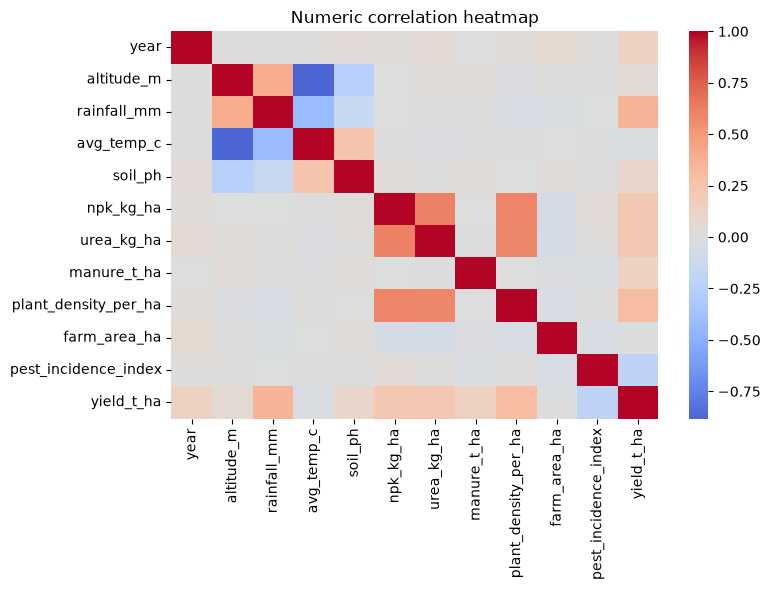

In [3]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
from src.config import RAW_FILE, DOCS_DIR, FIGURE_DIR
from src.cleaning import to_string_df, parse_number
DOCS_DIR.mkdir(parents=True, exist_ok=True); FIGURE_DIR.mkdir(parents=True, exist_ok=True)
df = to_string_df(RAW_FILE)
issues = []
def add(problem, columns, count, severity, treatment):
    issues.append({'problem': problem, 'columns_affected': columns, 'records_affected': int(count), 'severity': severity, 'proposed_treatment': treatment})
add('Exact duplicate rows', 'all', df.duplicated().sum(), 'High', 'Remove exact duplicates')
add('Repeated record identifiers', 'record_id', df['record_id'].duplicated().sum(), 'High', 'Keep the most complete record')
add('Missing values', 'rainfall_mm,soil_ph,pest_incidence_index', sum(parse_number(df[c]).isna().sum() for c in ['rainfall_mm','soil_ph','pest_incidence_index']), 'Medium', 'Fit training-only imputers')
add('Invalid target or area', 'yield_t_ha,farm_area_ha', ((parse_number(df['yield_t_ha']) <= 0) | (parse_number(df['farm_area_ha']) <= 0)).sum(), 'High', 'Set invalid values missing and drop missing targets')
add('Out-of-range pest index', 'pest_incidence_index', ((parse_number(df['pest_incidence_index']) < 0) | (parse_number(df['pest_incidence_index']) > 1)).sum(), 'Medium', 'Set invalid values missing')
add('Potential target leakage', 'yield_t_ha', df['yield_t_ha'].notna().sum(), 'High', 'Keep only as target; never include it in X')
quality = pd.DataFrame(issues)
quality.to_csv(DOCS_DIR / 'data_quality_report.csv', index=False)
(DOCS_DIR / 'data_quality_report.md').write_text('# Q1 Data Quality Report\n\n' + quality.to_string(index=False))
display(quality)
for col in ['yield_t_ha','rainfall_mm','avg_temp_c','npk_kg_ha']:
    plt.figure(figsize=(6,4)); sns.histplot(parse_number(df[col]), kde=True); plt.title(col); plt.tight_layout(); plt.savefig(FIGURE_DIR / f'hist_{col}.png'); display(plt.gcf()); plt.close()
plt.figure(figsize=(8,4)); sns.boxplot(data=df, x='season', y=parse_number(df['yield_t_ha'])); plt.title('Yield by season'); plt.tight_layout(); plt.savefig(FIGURE_DIR / 'box_yield_season.png'); display(plt.gcf()); plt.close()
numeric = pd.DataFrame({c: parse_number(df[c]) for c in ['year','altitude_m','rainfall_mm','avg_temp_c','soil_ph','npk_kg_ha','urea_kg_ha','manure_t_ha','plant_density_per_ha','farm_area_ha','pest_incidence_index','yield_t_ha']})
plt.figure(figsize=(8,6)); sns.heatmap(numeric.corr(), cmap='coolwarm', center=0); plt.title('Numeric correlation heatmap'); plt.tight_layout(); plt.savefig(FIGURE_DIR / 'heatmap_corr.png'); display(plt.gcf()); plt.close()


## Step 4 — Clean and preprocess

The explanation below describes this step before the code runs.

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q1 | Stage: 4: cleaning and preprocessing

Clean source values, derive canonical units, split by season, and fit preprocessing only on the training partition. The low-yield risk label is created after the split from the training 20th percentile and is excluded from the model inputs, so the risk question in E does not leak the harvest result.

In [4]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd, joblib
from src.config import RAW_FILE, INTERIM_DIR, PROCESSED_DIR, DOCS_DIR, TARGET_COL
from src.cleaning import to_string_df, clean_q1, add_time_features
from src.features import engineer_features
from src.logging_utils import CleaningLog
from src.pipeline import split_train_val_test, build_preprocessor, transform_split, add_low_yield_label
for p in [INTERIM_DIR, PROCESSED_DIR, DOCS_DIR]: p.mkdir(parents=True, exist_ok=True)
clog = CleaningLog()
clean = engineer_features(add_time_features(clean_q1(to_string_df(RAW_FILE), clog)))
clean.to_csv(INTERIM_DIR / 'maize_clean.csv', index=False)
train_df, val_df, test_df = split_train_val_test(clean)
q20 = add_low_yield_label(train_df, val_df, test_df)
pre, feature_cols = build_preprocessor(train_df)
joblib.dump({'preprocessor': pre, 'feature_cols': feature_cols, 'q20_threshold': q20}, PROCESSED_DIR / 'preprocessor.joblib')
for src, name in [(train_df,'train'), (val_df,'validation'), (test_df,'test')]:
    X = transform_split(pre, src, feature_cols)
    pd.concat([src[['record_id', TARGET_COL, 'low_yield_risk']].reset_index(drop=True), X.reset_index(drop=True)], axis=1).to_csv(PROCESSED_DIR / f'{name}_model_ready.csv', index=False)
    src.to_csv(PROCESSED_DIR / f'{name}_clean_unscaled.csv', index=False)
clog.save(DOCS_DIR / 'cleaning_log.csv', DOCS_DIR / 'cleaning_log.md')
print('Split shapes:', train_df.shape, val_df.shape, test_df.shape)
print('Low-yield threshold (training 20th percentile):', round(q20, 1), 'kg/ha')
print('low_yield_risk in model features:', 'low_yield_risk' in feature_cols)


Split shapes: (998, 37) (214, 37) (214, 37)
Low-yield threshold (training 20th percentile): 1950.0 kg/ha
low_yield_risk in model features: False


## Step 5 — Engineer and select features

The explanation below describes this step before the code runs.

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q1 | Stage: 5: feature engineering and selection

Review revised-dataset features using training data only; the target and source target column never enter the candidate inputs.

In [5]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from sklearn.feature_selection import mutual_info_regression
from src.config import DOCS_DIR, LEAKAGE_COLS, PROCESSED_DIR, TARGET_COL
from src.features import rf_importance, select_features_numeric
DOCS_DIR.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(PROCESSED_DIR / 'train_clean_unscaled.csv')
excluded = {'record_id', TARGET_COL, 'yield_t_ha', *LEAKAGE_COLS}
X = train[[c for c in train.columns if c not in excluded]]
num = X.select_dtypes(include='number')
kept, selected = select_features_numeric(num, train[TARGET_COL], k=15)
mi = mutual_info_regression(num.fillna(num.median()), train[TARGET_COL], random_state=42)
mi_df = pd.DataFrame({'feature': num.columns, 'mutual_info': mi}).sort_values('mutual_info', ascending=False)
mi_df.to_csv(DOCS_DIR / 'mutual_information.csv', index=False)
rf_importance(X, train[TARGET_COL]).to_csv(DOCS_DIR / 'rf_importance.csv', index=False)
pd.DataFrame({'variance_kept': pd.Series(kept), 'selected_by_f_regression': pd.Series(selected)}).to_csv(DOCS_DIR / 'feature_selection.csv', index=False)

justification = pd.DataFrame([
 ('fertilizer_kg_per_ha', 'Created', 'NPK + urea + manure converted to one kg/ha rate', 'B'),
 ('is_improved_seed', 'Created', '1 when seed_variety is not Local; 0 for local seed', 'B'),
 ('altitude_band', 'Created', 'Lowland, mid, or highland band', 'C'),
 ('temp_deviation_from_optimum', 'Created', 'Degrees outside the 18-27 C band', 'C'),
 ('rain_per_temp', 'Created', 'Rainfall divided by average temperature', 'C'),
 ('rainfall_log', 'Created', 'Log transform of rainfall', 'C'),
 ('fertilizer_log1p', 'Created', 'Log transform of fertiliser rate', 'B'),
 ('farm_size_log', 'Created', 'Log transform of farm area', 'A'),
 ('irrigated_flag', 'Created', '1 when irrigation is recorded as Yes', 'C'),
 ('season_x_irrigation', 'Created', 'Season and irrigation combined', 'C/D'),
 ('low_yield_risk', 'Label only', 'Bottom 20% of training yield; excluded from X', 'E'),
], columns=['feature', 'status', 'definition', 'question'])
justification.to_csv(DOCS_DIR / 'feature_justification.csv', index=False)
(DOCS_DIR / 'feature_justification.md').write_text('# Q1 Feature Justification' + chr(10) + chr(10) + justification.to_string(index=False) + chr(10))
print('Excluded from model inputs:', sorted(excluded))
display(mi_df.head(15))


Excluded from model inputs: ['low_yield_risk', 'record_id', 'yield_kg_per_ha', 'yield_t_ha']


,feature,mutual_info
15,is_improved_seed,0.207041
13,rainfall_per_temp,0.118724
17,rain_per_temp,0.118589
2,rainfall_mm,0.082295
18,rainfall_log,0.082164
5,npk_kg_ha,0.065930
8,plant_density_per_ha,0.053865
10,pest_incidence_index,0.035864
3,avg_temp_c,0.030817
6,urea_kg_ha,0.030197


### Reading the output

The target `yield_kg_per_ha`, its source `yield_t_ha`, and the derived `low_yield_risk` label are absent from the candidate inputs. The mutual-information and random-forest rankings therefore describe pre-harvest predictors rather than the harvest result. `is_improved_seed` now comes from `seed_variety` (hybrid versus Local), not from the farming-practice label.

## Step 6 — Finalise and verify outputs

The explanation below describes this step before the code runs.

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q1 | Stage: 6: finalise

Package the revised Q1 outputs and document the new target, source fields, cleaning decisions, and limitations.

In [6]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
from src.config import DOCS_DIR, PROCESSED_DIR, TARGET_COL
from src.cleaning import to_string_df
import pandas as pd
train = pd.read_csv(PROCESSED_DIR / 'train_model_ready.csv')
val = pd.read_csv(PROCESSED_DIR / 'validation_model_ready.csv')
test = pd.read_csv(PROCESSED_DIR / 'test_model_ready.csv')
summary = f'''# Q1 Data Card

- Target: `{TARGET_COL}` (derived from source `yield_t_ha` by multiplying by 1,000).
- Records: train={len(train)}, validation={len(val)}, test={len(test)}.
- Revised source fields: record ID, year, season, geography, weather, soil, seed, farming practice, fertiliser, density, area, irrigation and pest index.
- Leakage control: `yield_t_ha` and the derived `low_yield_risk` label are excluded from model features; no harvest-weight field is present in the revised source.
- Cooperative answers: `docs/cooperative_answers.md` reports the evidence for questions A-E.
- Prepared: {date.today().isoformat()}.
- Limitation: this is a prepared dataset, not a trained or deployed prediction model.
'''
(DOCS_DIR / 'data_card.md').write_text(summary)
(DOCS_DIR / 'memo_to_manager.md').write_text('''# Memo to Manager

The revised Rwanda maize dataset contains 1,426 observations and 20 source columns. The Q1 workflow uses `yield_t_ha` as the target and converts it to `yield_kg_per_ha`. It derives total fertiliser from NPK, urea and manure per hectare, uses `farm_area_ha`, and maps the pest index into an ordinal category. Missing values are handled by training-fitted preprocessing; the source target and the derived `low_yield_risk` label are excluded from model inputs. The notebook now reports evidence for the cooperative questions A-E, but this repository still does not train a production model.
''')
print(summary)


# Q1 Data Card

- Target: `yield_kg_per_ha` (derived from source `yield_t_ha` by multiplying by 1,000).
- Records: train=998, validation=214, test=214.
- Revised source fields: record ID, year, season, geography, weather, soil, seed, farming practice, fertiliser, density, area, irrigation and pest index.
- Leakage control: `yield_t_ha` and the derived `low_yield_risk` label are excluded from model features; no harvest-weight field is present in the revised source.
- Cooperative answers: `docs/cooperative_answers.md` reports the evidence for questions A-E.
- Prepared: 2026-11-12.
- Limitation: this is a prepared dataset, not a trained or deployed prediction model.



## Step 7 — Answer the cooperative questions

The explanation below describes this step before the code runs.

Group Achille-Sylvie | Members: Cishahayo Songa Achille, Umwiza Sylvie | Question: Q1 | Stage: 7: answers to the cooperative questions

Steps 1-6 prepared the dataset. This step uses the cleaned farm records to answer the five questions the cooperative asked. Each subsection gives the evidence, a chart, and the practical answer.

| Question | What the cooperative must be able to do | Answered in |
| --- | --- | --- |
| A | Plan storage, transport and sales from a reliable yield per hectare | 7A |
| B | Decide whether fertiliser and improved seed raise yield, compared fairly | 7B |
| C | Understand weather, altitude and irrigation risk | 7C |
| D | Target support by province, district and season | 7D |
| E | Identify farms at high risk of a very low harvest before harvest | 7E |

The data are observational: 1,426 farm records, not a controlled experiment. The answers describe associations in this dataset. They do not prove that one input causes a yield change, and they should not be presented as guaranteed outcomes.

In [7]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.config import DOCS_DIR, FIGURE_DIR, INTERIM_DIR, PROCESSED_DIR, TARGET_COL

DOCS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

clean = pd.read_csv(INTERIM_DIR / 'maize_clean.csv')
clean['yield_t_ha_clean'] = clean[TARGET_COL] / 1000
clean['seed_type'] = np.where(clean['seed_variety'].eq('Local'), 'Local', 'Hybrid')
clean['fert_tercile'] = pd.qcut(clean['fertilizer_kg_per_ha'], 3, labels=['low', 'mid', 'high'])
clean['rain_quartile'] = pd.qcut(clean['rainfall_mm'], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
clean['temp_band'] = pd.cut(clean['avg_temp_c'], bins=[-np.inf, 18, 22, 26, np.inf], labels=['<18 C', '18-22 C', '22-26 C', '>26 C'])

bundle = joblib.load(PROCESSED_DIR / 'preprocessor.joblib')
feature_cols = bundle['feature_cols']
q20 = bundle['q20_threshold']
clean['risk_label'] = (clean[TARGET_COL] < q20).astype(int)

print('Cleaned records:', len(clean))
print('Training low-yield threshold:', round(q20, 1), 'kg/ha =', round(q20 / 1000, 2), 't/ha')
print('Share below threshold in the cleaned data:', round(100 * clean['risk_label'].mean(), 1), '%')
print('Model feature count:', len(feature_cols))


Cleaned records: 1426
Training low-yield threshold: 1950.0 kg/ha = 1.95 t/ha
Share below threshold in the cleaned data: 19.8 %
Model feature count: 33


### 7A — How much maize can a farm expect per hectare?

**What you are looking at:** the cleaned yield distribution and the average for each province and season. These are the values a planner can use for storage, transport and sales.

**How it works:** the source `yield_t_ha` is converted to kg/ha, then shown in tonnes/ha for readability. The cleaned series is winsorized at the 1st and 99th percentiles, so a few entry errors cannot dominate the average.

,tonnes_per_ha
count,1426.00
mean,2.57
std,0.69
min,1.20
10%,1.67
25%,2.06
50%,2.58
75%,3.04
90%,3.48
max,4.27


,province,season,n,mean_t_ha,median_t_ha
0,Eastern,A,140,2.74,2.80
1,Eastern,B,140,2.40,2.41
2,Eastern,C,48,1.89,1.91
3,Kigali,A,40,2.75,2.82
4,Kigali,B,40,2.53,2.36
5,Kigali,C,6,1.91,1.87
6,Northern,A,100,2.78,2.68
7,Northern,B,100,2.67,2.64
8,Northern,C,30,2.04,2.06
9,Southern,A,180,2.99,3.00


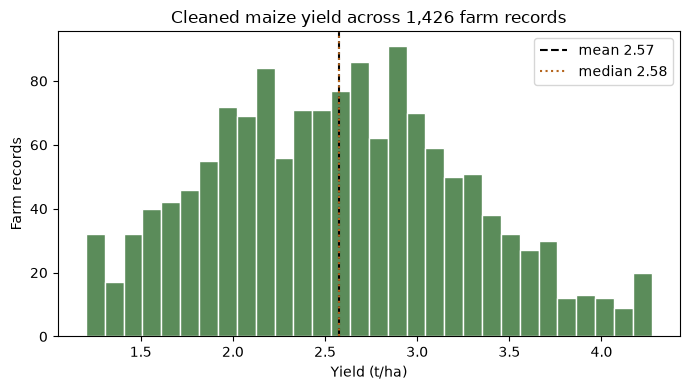

In [8]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

yield_stats = clean['yield_t_ha_clean'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).to_frame('tonnes_per_ha').round(2)
display(yield_stats)

province_season = (
    clean.groupby(['province', 'season'])
    .agg(n=('yield_t_ha_clean', 'size'), mean_t_ha=('yield_t_ha_clean', 'mean'), median_t_ha=('yield_t_ha_clean', 'median'))
    .round(2)
    .reset_index()
)
display(province_season)

mean_yield = clean['yield_t_ha_clean'].mean()
median_yield = clean['yield_t_ha_clean'].median()
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(clean['yield_t_ha_clean'].dropna(), bins=30, color='#5b8c5a', edgecolor='white')
ax.axvline(mean_yield, color='black', linestyle='--', label='mean ' + str(round(mean_yield, 2)))
ax.axvline(median_yield, color='#b5651d', linestyle=':', label='median ' + str(round(median_yield, 2)))
ax.set_title('Cleaned maize yield across 1,426 farm records')
ax.set_xlabel('Yield (t/ha)')
ax.set_ylabel('Farm records')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'q1_yield_distribution.png', dpi=120)
display(fig)
plt.close(fig)


**Answer A.** The mean is **2.57 t/ha** and the median is **2.58 t/ha**. The central 80% of records lies between **1.68 and 3.48 t/ha** after cleaning. Province means are close together (2.47-2.65 t/ha), but season is a much larger difference: A **2.86**, B **2.51**, C **2.00 t/ha**. A cooperative can use about **2.6 t/ha** as an overall planning figure, but should use the season-specific and province-specific rows when planning a particular delivery window. Each model-ready row also keeps its own farm-level target, so the dataset supports a per-farm estimate in the next modelling phase.

### 7B — Do fertiliser and improved seed really increase yield?

**What you are looking at:** three fair comparisons — hybrid versus local seed, improved versus traditional practice, and low versus high fertiliser rate. The fertiliser measure is **kg/ha**, so a large farm and a small farm are compared at the same rate rather than on total bags purchased.

**How it works:** `is_improved_seed` is now derived from `seed_variety` (any variety other than `Local` is hybrid), not from the farming-practice label. Fertiliser is NPK + urea + manure converted to one kg/ha rate. The cross-tab of practice and seed type checks whether the seed difference survives inside each practice group.

,n,mean_t_ha,median_t_ha
seed_type,,,
Hybrid,1145,2.76,2.74
Local,281,1.80,1.77


,n,mean_t_ha,median_t_ha
farming_practice,,,
Improved,783,2.74,2.73
Traditional,643,2.37,2.37


,n,mean_fert_kg_ha,mean_t_ha
fert_tercile,,,
low,476,705.84,2.48
mid,475,2130.18,2.54
high,475,3716.89,2.70


seed_type,Hybrid,Local
farming_practice,,
Improved,2.93,1.96
Traditional,2.56,1.61


,comparison,group_a_mean_t_ha,group_b_mean_t_ha,difference_t_ha,difference_%
0,Hybrid seed vs local seed,2.76,1.80,0.96,53.5
1,Improved vs traditional practice,2.74,2.37,0.38,15.9
2,High vs low fertiliser tercile,2.70,2.48,0.22,9.0


,check,result
0,Fertiliser unit,"kg/ha, so farm size is removed from the compar..."
1,Correlation: fertiliser rate vs farm size,-0.021


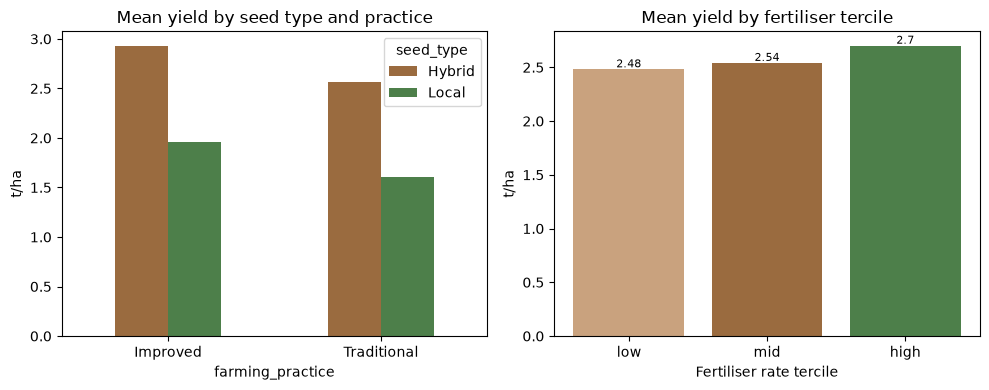

In [9]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

seed_summary = clean.groupby('seed_type').agg(n=('yield_t_ha_clean', 'size'), mean_t_ha=('yield_t_ha_clean', 'mean'), median_t_ha=('yield_t_ha_clean', 'median')).round(2)
practice_summary = clean.groupby('farming_practice').agg(n=('yield_t_ha_clean', 'size'), mean_t_ha=('yield_t_ha_clean', 'mean'), median_t_ha=('yield_t_ha_clean', 'median')).round(2)
fert_summary = clean.groupby('fert_tercile', observed=True).agg(n=('yield_t_ha_clean', 'size'), mean_fert_kg_ha=('fertilizer_kg_per_ha', 'mean'), mean_t_ha=('yield_t_ha_clean', 'mean')).round(2)
practice_seed = clean.pivot_table(index='farming_practice', columns='seed_type', values='yield_t_ha_clean', aggfunc='mean').round(2)

display(seed_summary)
display(practice_summary)
display(fert_summary)
display(practice_seed)

hybrid_mean = clean.loc[clean['seed_type'].eq('Hybrid'), 'yield_t_ha_clean'].mean()
local_mean = clean.loc[clean['seed_type'].eq('Local'), 'yield_t_ha_clean'].mean()
improved_mean = clean.loc[clean['farming_practice'].eq('Improved'), 'yield_t_ha_clean'].mean()
traditional_mean = clean.loc[clean['farming_practice'].eq('Traditional'), 'yield_t_ha_clean'].mean()
low_fert_mean = clean.loc[clean['fert_tercile'].eq('low'), 'yield_t_ha_clean'].mean()
high_fert_mean = clean.loc[clean['fert_tercile'].eq('high'), 'yield_t_ha_clean'].mean()

comparisons = pd.DataFrame([
    {'comparison': 'Hybrid seed vs local seed', 'group_a_mean_t_ha': round(hybrid_mean, 2), 'group_b_mean_t_ha': round(local_mean, 2), 'difference_t_ha': round(hybrid_mean - local_mean, 2), 'difference_%': round(100 * (hybrid_mean / local_mean - 1), 1)},
    {'comparison': 'Improved vs traditional practice', 'group_a_mean_t_ha': round(improved_mean, 2), 'group_b_mean_t_ha': round(traditional_mean, 2), 'difference_t_ha': round(improved_mean - traditional_mean, 2), 'difference_%': round(100 * (improved_mean / traditional_mean - 1), 1)},
    {'comparison': 'High vs low fertiliser tercile', 'group_a_mean_t_ha': round(high_fert_mean, 2), 'group_b_mean_t_ha': round(low_fert_mean, 2), 'difference_t_ha': round(high_fert_mean - low_fert_mean, 2), 'difference_%': round(100 * (high_fert_mean / low_fert_mean - 1), 1)},
])
display(comparisons)

size_check = pd.DataFrame([
    {'check': 'Fertiliser unit', 'result': 'kg/ha, so farm size is removed from the comparison'},
    {'check': 'Correlation: fertiliser rate vs farm size', 'result': round(clean[['fertilizer_kg_per_ha', 'farm_area_ha']].corr().iloc[0, 1], 3)},
])
display(size_check)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
practice_seed.plot(kind='bar', ax=axes[0], color=['#9a6b3f', '#4d7f4a'])
axes[0].set_title('Mean yield by seed type and practice')
axes[0].set_ylabel('t/ha')
axes[0].tick_params(axis='x', rotation=0)
axes[1].bar(fert_summary.index.astype(str), fert_summary['mean_t_ha'], color=['#c9a27e', '#9a6b3f', '#4d7f4a'])
axes[1].set_title('Mean yield by fertiliser tercile')
axes[1].set_xlabel('Fertiliser rate tercile')
axes[1].set_ylabel('t/ha')
for i, value in enumerate(fert_summary['mean_t_ha']):
    axes[1].text(i, value + 0.02, str(round(value, 2)), ha='center', fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'q1_inputs_and_yield.png', dpi=120)
display(fig)
plt.close(fig)


**Answer B.** Yes, in these records both choices are associated with higher yield, but the seed difference is much larger. Hybrid seed averages **2.76 t/ha** against **1.80** for local seed, a difference of **+0.96 t/ha (+53%)**. The gap persists inside both practice groups: improved practice 2.93 vs 1.96 t/ha; traditional practice 2.56 vs 1.61 t/ha. Improved practice averages **2.74 vs 2.37 t/ha (+0.37, +16%)**. Moving from the lowest to the highest fertiliser tercile raises the mean from **2.48 to 2.70 t/ha (+0.22, +9%)**. The fertiliser rate is already per hectare, and its correlation with farm size is about **-0.02**, so the comparison is not being driven by farm size. These are observational comparisons: seed choice and fertiliser use may also reflect better management or better land, so the cooperative should not read the differences as guaranteed causal effects.

### 7C — How do rainfall, temperature, altitude and irrigation affect yield?

**What you are looking at:** rank correlations with yield and group means for rainfall quartiles, temperature bands, altitude bands, and irrigation. Correlation is on a -1 to +1 scale: values near zero mean no clear straight-line relationship.

**How it works:** Spearman correlation is used because it does not assume a straight-line relationship and is less sensitive to extreme values. Group means show the practical shape. Rainfall is split into quartiles; temperature and altitude use simple bands.

,variable,spearman,pearson
0,rainfall_mm,0.347,0.367
5,plant_density_per_ha,0.284,0.295
4,fertilizer_kg_per_ha,0.137,0.148
3,soil_ph,0.102,0.095
2,altitude_m,0.046,0.045
7,farm_area_ha,-0.000,-0.007
1,avg_temp_c,-0.022,-0.026
6,pest_incidence_index,-0.197,-0.217


,check,result
0,Rainfall range (mm),150.0 to 835.7
1,Rainfall missing,11
2,Temperature range (C),15.4 to 23.0
3,Temperature missing,0
4,Altitude range (m),1243.0 to 2341.0
5,Altitude missing,0
6,Irrigation values,"No, Yes"
7,Irrigation records,128 Yes / 1298 No


,group,category,n,mean_t_ha
0,Rainfall quartile,Q1,354,2.12
1,Rainfall quartile,Q2,354,2.63
2,Rainfall quartile,Q3,353,2.75
3,Rainfall quartile,Q4,354,2.80
4,Temperature band,<18 C,357,2.54
5,Temperature band,18-22 C,1009,2.60
6,Temperature band,22-26 C,60,2.33
7,Altitude band,highland,127,2.52
8,Altitude band,lowland,105,2.49
9,Altitude band,mid,1194,2.59


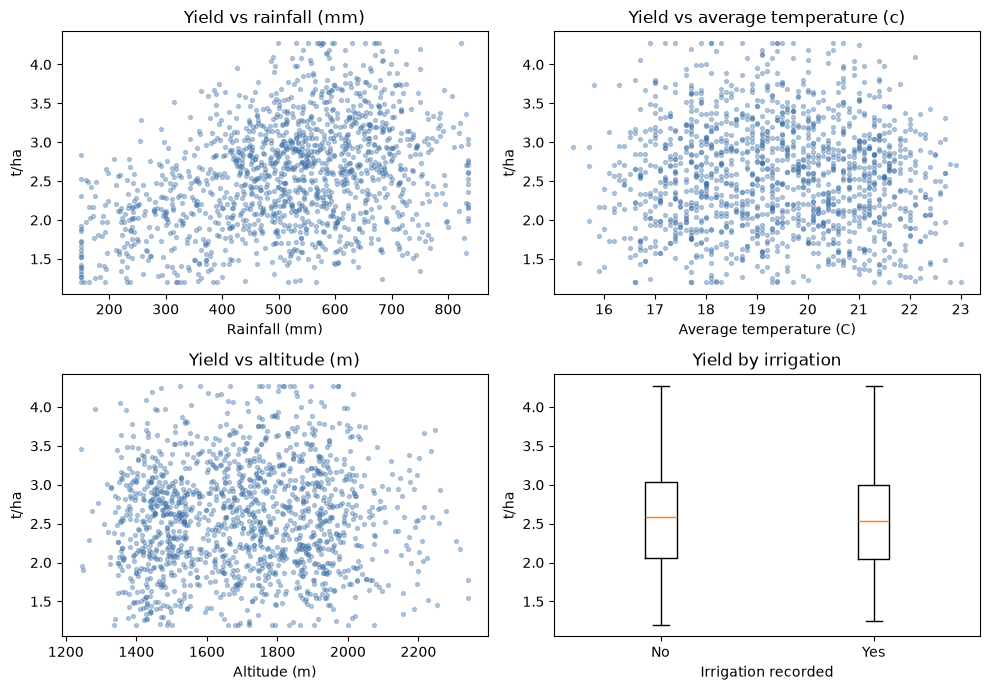

In [10]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

variables = ['rainfall_mm', 'avg_temp_c', 'altitude_m', 'soil_ph', 'fertilizer_kg_per_ha', 'plant_density_per_ha', 'pest_incidence_index', 'farm_area_ha']
corr_rows = []
for variable in variables:
    pair = clean[[variable, TARGET_COL]].dropna()
    corr_rows.append({'variable': variable, 'spearman': pair.corr(method='spearman').iloc[0, 1], 'pearson': pair.corr().iloc[0, 1]})
corr_table = pd.DataFrame(corr_rows).round(3).sort_values('spearman', ascending=False)
display(corr_table)

weather_check = pd.DataFrame([
    {'check': 'Rainfall range (mm)', 'result': str(round(clean['rainfall_mm'].min(), 1)) + ' to ' + str(round(clean['rainfall_mm'].max(), 1))},
    {'check': 'Rainfall missing', 'result': int(clean['rainfall_mm'].isna().sum())},
    {'check': 'Temperature range (C)', 'result': str(round(clean['avg_temp_c'].min(), 1)) + ' to ' + str(round(clean['avg_temp_c'].max(), 1))},
    {'check': 'Temperature missing', 'result': int(clean['avg_temp_c'].isna().sum())},
    {'check': 'Altitude range (m)', 'result': str(round(clean['altitude_m'].min(), 0)) + ' to ' + str(round(clean['altitude_m'].max(), 0))},
    {'check': 'Altitude missing', 'result': int(clean['altitude_m'].isna().sum())},
    {'check': 'Irrigation values', 'result': ', '.join(sorted(clean['irrigation'].unique()))},
    {'check': 'Irrigation records', 'result': str(int(clean['irrigation'].eq('Yes').sum())) + ' Yes / ' + str(int(clean['irrigation'].eq('No').sum())) + ' No'},
])
display(weather_check)

def group_means(column, label):
    table = clean.groupby(column, observed=True).agg(n=('yield_t_ha_clean', 'size'), mean_t_ha=('yield_t_ha_clean', 'mean')).reset_index()
    table.columns = ['category', 'n', 'mean_t_ha']
    table.insert(0, 'group', label)
    return table

group_table = pd.concat([
    group_means('rain_quartile', 'Rainfall quartile'),
    group_means('temp_band', 'Temperature band'),
    group_means('altitude_band', 'Altitude band'),
    group_means('irrigation', 'Irrigation'),
], ignore_index=True)
display(group_table.round(2))

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
panels = [('rainfall_mm', 'Rainfall (mm)'), ('avg_temp_c', 'Average temperature (C)'), ('altitude_m', 'Altitude (m)')]
for ax, (column, label) in zip(axes.flat[:3], panels):
    ax.scatter(clean[column], clean['yield_t_ha_clean'], s=8, alpha=0.35, color='#3b6ea5')
    ax.set_title('Yield vs ' + label.lower())
    ax.set_xlabel(label)
    ax.set_ylabel('t/ha')
no_irrigation = clean.loc[clean['irrigation'].eq('No'), 'yield_t_ha_clean'].dropna()
yes_irrigation = clean.loc[clean['irrigation'].eq('Yes'), 'yield_t_ha_clean'].dropna()
axes[1, 1].boxplot([no_irrigation, yes_irrigation])
axes[1, 1].set_xticks([1, 2], ['No', 'Yes'])
axes[1, 1].set_title('Yield by irrigation')
axes[1, 1].set_xlabel('Irrigation recorded')
axes[1, 1].set_ylabel('t/ha')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'q1_weather_location_yield.png', dpi=120)
display(fig)
plt.close(fig)


**Answer C.** Rainfall has the clearest positive association: Spearman **+0.35**, with mean yield rising from **2.12 t/ha** in the driest quartile to **2.80 t/ha** in the wettest. Temperature has almost no linear association (**-0.02**): the 18-22 C band averages 2.60 t/ha, while the small 22-26 C group averages 2.33. Altitude is weak (**+0.05**), with mid-altitude farms highest at 2.59 t/ha. Irrigation shows **2.53 t/ha with irrigation vs 2.58 without**, so these records do not show an irrigation advantage; only 128 farms are irrigated and irrigation may be used on poorer or drier land, so this is not evidence that irrigation fails. Pest incidence (**-0.20**) and plant density (**+0.28**) are stronger correlates than temperature or altitude. The cooperative should treat rainfall and pest pressure as the main weather-related risks.

### 7D — Do results differ between provinces, districts and seasons?

**What you are looking at:** label consistency, a province and season summary, the five lowest and five highest district averages (districts with at least 20 records), and a province-by-season chart.

**How it works:** before comparing groups, the step checks that each district has one province label and that season uses only A, B and C. The source has no planting-date column, so this notebook can compare seasons but cannot verify or correct planting dates.

,check,value,expected
0,District labels,30,"30, one label per district"
1,Season labels,"A, B, C","A, B and C only"
2,Districts mapped to more than one province,0,0
3,Planting-date fields in source,0,not available; only season is recorded


,n,mean_t_ha,median_t_ha
province,,,
Eastern,328,2.47,2.52
Western,348,2.54,2.54
Kigali,86,2.59,2.58
Northern,230,2.63,2.58
Southern,434,2.65,2.65


,n,mean_t_ha,median_t_ha
season,,,
A,600,2.86,2.88
B,600,2.51,2.51
C,226,2.00,2.01


,province,district,n,mean_t_ha
1,Eastern,Gatsibo,46,2.34
5,Eastern,Nyagatare,48,2.35
18,Southern,Nyamagabe,48,2.38
28,Western,Rusizi,48,2.41
25,Western,Nyabihu,50,2.41
15,Southern,Huye,52,2.71
14,Southern,Gisagara,48,2.72
9,Northern,Burera,42,2.74
22,Southern,Ruhango,50,2.80
17,Southern,Muhanga,44,2.83


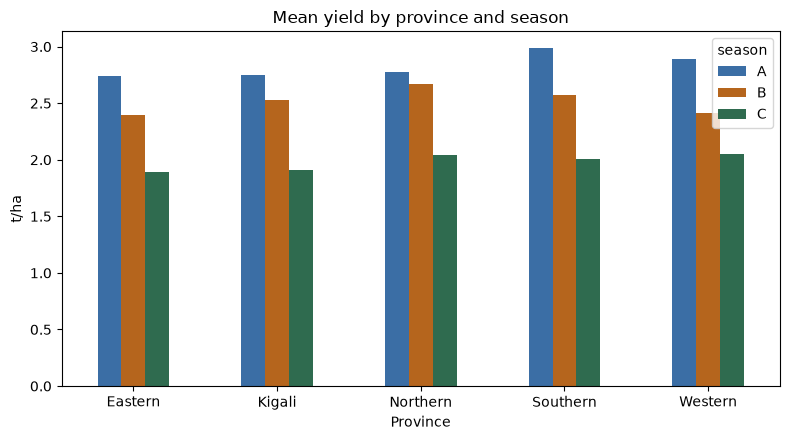

In [11]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

district_provinces = clean.groupby('district')['province'].nunique()
consistency = pd.DataFrame([
    {'check': 'District labels', 'value': clean['district'].nunique(), 'expected': '30, one label per district'},
    {'check': 'Season labels', 'value': ', '.join(sorted(clean['season'].unique())), 'expected': 'A, B and C only'},
    {'check': 'Districts mapped to more than one province', 'value': int((district_provinces > 1).sum()), 'expected': '0'},
    {'check': 'Planting-date fields in source', 'value': 0, 'expected': 'not available; only season is recorded'},
])
display(consistency)

province_summary = clean.groupby('province').agg(n=('yield_t_ha_clean', 'size'), mean_t_ha=('yield_t_ha_clean', 'mean'), median_t_ha=('yield_t_ha_clean', 'median')).round(2).sort_values('mean_t_ha')
season_summary = clean.groupby('season').agg(n=('yield_t_ha_clean', 'size'), mean_t_ha=('yield_t_ha_clean', 'mean'), median_t_ha=('yield_t_ha_clean', 'median')).round(2)
district_summary = clean.groupby(['province', 'district']).agg(n=('yield_t_ha_clean', 'size'), mean_t_ha=('yield_t_ha_clean', 'mean')).reset_index()
district_summary = district_summary[district_summary['n'] >= 20].sort_values('mean_t_ha').round(2)
display(province_summary)
display(season_summary)
display(pd.concat([district_summary.head(5), district_summary.tail(5)]))

pivot = clean.pivot_table(index='province', columns='season', values='yield_t_ha_clean', aggfunc='mean')
fig, ax = plt.subplots(figsize=(8, 4.5))
pivot.plot(kind='bar', ax=ax, color=['#3b6ea5', '#b5651d', '#2f6b4f'])
ax.set_title('Mean yield by province and season')
ax.set_ylabel('t/ha')
ax.set_xlabel('Province')
ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'q1_province_season_yield.png', dpi=120)
display(fig)
plt.close(fig)


**Answer D.** Yes, results differ, but season matters more than province. Season A averages **2.86 t/ha**, season B **2.51**, and season C **2.00**. Province means range only from **2.47 (Eastern) to 2.65 (Southern)**. Among districts with at least 20 records, the range is **2.34 (Gatsibo) to 2.83 (Muhanga)**. The labels are consistent: 30 districts, each mapped to exactly one province, and only seasons A/B/C. Planting dates are not in the source, so the cooperative cannot use this dataset to compare early versus late planting; that is a data-collection gap to fix if date-level advice is needed.

### 7E — Which farms are at high risk of a very low harvest?

**What you are looking at:** the share of farms below the low-yield threshold, broken down by province, season, seed type, fertiliser rate, irrigation and practice. The threshold is the **training-set 20th percentile**, not a fixed national cut-off.

**How it works:** the threshold is learned from the training split only, then applied to all records for reporting. The audit table confirms that the target and the derived risk label are **not** in the model feature set. All inputs are known before harvest: location, season, weather, soil, seed, practice, fertiliser, density, area and pest index.

,group,category,n,risk_rate_%
0,Province,Eastern,328,24.1
1,Province,Kigali,86,16.3
2,Province,Northern,230,18.7
3,Province,Southern,434,16.1
4,Province,Western,348,22.1
5,Season,A,600,10.5
6,Season,B,600,19.8
7,Season,C,226,44.7
8,Seed type,Hybrid,1145,8.9
9,Seed type,Local,281,64.4


,check,result
0,Features passed to the preprocessor,33
1,Target-derived fields inside the feature set,none
2,Risk label,kept as an output column only
3,Post-harvest source fields,none


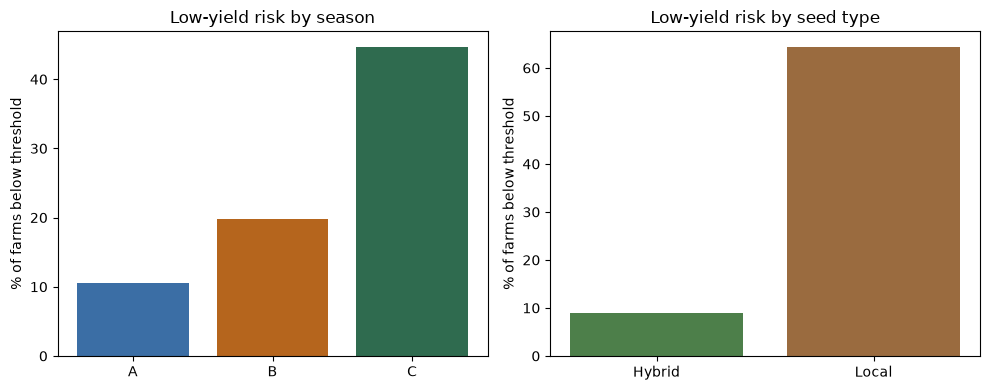

In [12]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

risk_rows = []
for column, label in [('province', 'Province'), ('season', 'Season'), ('seed_type', 'Seed type'), ('fert_tercile', 'Fertiliser tercile'), ('irrigation', 'Irrigation'), ('farming_practice', 'Farming practice')]:
    table = clean.groupby(column, observed=True).agg(n=('risk_label', 'size'), risk_rate=('risk_label', 'mean')).reset_index()
    table.columns = ['category', 'n', 'risk_rate']
    table.insert(0, 'group', label)
    risk_rows.append(table)
risk_table = pd.concat(risk_rows, ignore_index=True)
risk_table['risk_rate_%'] = (100 * risk_table['risk_rate']).round(1)
display(risk_table[['group', 'category', 'n', 'risk_rate_%']])

leakage_hits = sorted(set(feature_cols) & {TARGET_COL, 'yield_t_ha', 'low_yield_risk'})
audit = pd.DataFrame([
    {'check': 'Features passed to the preprocessor', 'result': len(feature_cols)},
    {'check': 'Target-derived fields inside the feature set', 'result': ', '.join(leakage_hits) if leakage_hits else 'none'},
    {'check': 'Risk label', 'result': 'kept as an output column only'},
    {'check': 'Post-harvest source fields', 'result': 'none'},
])
display(audit)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
season_risk = 100 * clean.groupby('season')['risk_label'].mean()
axes[0].bar(season_risk.index, season_risk.values, color=['#3b6ea5', '#b5651d', '#2f6b4f'])
axes[0].set_title('Low-yield risk by season')
axes[0].set_ylabel('% of farms below threshold')
seed_risk = 100 * clean.groupby('seed_type')['risk_label'].mean()
axes[1].bar(seed_risk.index, seed_risk.values, color=['#4d7f4a', '#9a6b3f'])
axes[1].set_title('Low-yield risk by seed type')
axes[1].set_ylabel('% of farms below threshold')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'q1_risk_groups.png', dpi=120)
display(fig)
plt.close(fig)


**Answer E.** The training threshold is **1.95 t/ha**, and **19.8%** of the cleaned records fall below it. Risk is concentrated: season C **44.7%**, season B 19.8%, season A 10.5%; local seed **64.4%** versus hybrid 8.9%; low fertiliser 22.3% versus high 14.3%; Eastern 24.1% and Western 22.1% versus Southern 16.1%. The early-support list should therefore start with season C, local-seed, low-fertiliser farms in Eastern and Western provinces. The leakage audit confirms the risk label and the harvest target are not model inputs, so this is a pre-harvest screening rule rather than a prediction that has already seen the result.

In [13]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

answers = pd.DataFrame([
    {'question': 'A. Expected maize yield per hectare', 'answer': 'About 2.6 t/ha overall; central 80% is 1.68-3.48 t/ha.', 'evidence': 'Section 7A: yield distribution and province x season table'},
    {'question': 'B. Do fertiliser and improved seed increase yield?', 'answer': 'Hybrid seed +0.96 t/ha (+53%); improved practice +0.37 t/ha (+16%); high vs low fertiliser +0.22 t/ha (+9%).', 'evidence': 'Section 7B: group means, practice x seed cross-tab, per-hectare fertiliser check'},
    {'question': 'C. Do rainfall, temperature, altitude and irrigation affect yield?', 'answer': 'Rainfall is the clear positive factor (+0.35); temperature and altitude are weak; irrigation shows no advantage in these records.', 'evidence': 'Section 7C: correlations and grouped means'},
    {'question': 'D. Do results differ by province, district and season?', 'answer': 'Season is the largest difference (A 2.86, B 2.51, C 2.00 t/ha); province 2.47-2.65; districts 2.34-2.83.', 'evidence': 'Section 7D: consistency checks, summaries and district range'},
    {'question': 'E. Which farms are at high risk of a very low harvest?', 'answer': 'Season C, local seed, low fertiliser, Eastern and Western farms have the highest risk; threshold 1.95 t/ha.', 'evidence': 'Section 7E: risk rates and leakage audit'},
])
display(answers)
answers.to_csv(DOCS_DIR / 'cooperative_answers.csv', index=False)

answer_doc = chr(10).join([
    '# Q1 Answers to the Cooperative Questions',
    '',
    'These answers use the cleaned 1,426-record maize dataset. They are observational associations, not causal proof.',
    '',
    '## A. How much maize can a farm expect per hectare?',
    'Mean 2.57 t/ha and median 2.58 t/ha; the central 80% is 1.68-3.48 t/ha. Province means are 2.47-2.65 t/ha. Season means are A 2.86, B 2.51 and C 2.00 t/ha.',
    '',
    '## B. Do fertiliser and improved seed increase yield?',
    'Hybrid seed averages 2.76 t/ha versus 1.80 for local seed (+0.96, +53%). Improved practice averages 2.74 versus 2.37 t/ha (+0.37, +16%). The highest fertiliser tercile averages 2.70 versus 2.48 t/ha in the lowest (+0.22, +9%). Fertiliser is measured per hectare, and its correlation with farm size is about -0.02, so the comparison is not driven by farm size.',
    '',
    '## C. How do rainfall, temperature, altitude and irrigation affect yield?',
    'Rainfall has the strongest positive association (Spearman +0.35; 2.12 t/ha in the driest quartile to 2.80 in the wettest). Temperature (-0.02) and altitude (+0.05) are weak. Irrigation averages 2.53 t/ha versus 2.58 without it in these records, but only 128 farms are irrigated and the group is not randomised. Pest incidence (-0.20) and plant density (+0.28) are stronger correlates than temperature or altitude.',
    '',
    '## D. Do results differ by province, district and season?',
    'Season is the largest difference: A 2.86, B 2.51 and C 2.00 t/ha. Province means range from 2.47 (Eastern) to 2.65 (Southern). Districts with at least 20 records range from 2.34 (Gatsibo) to 2.83 (Muhanga). There are 30 consistent district labels, each mapped to one province, and only seasons A/B/C. Planting dates are not in the source, so date-level comparisons are not possible.',
    '',
    '## E. Which farms are at high risk of a very low harvest?',
    'The training-set 20th percentile is 1.95 t/ha; 19.8% of cleaned records are below it. Risk is 44.7% in season C, 64.4% for local seed versus 8.9% for hybrid, 22.3% in the low fertiliser tercile versus 14.3% in the high tercile, and 24.1% in Eastern and 22.1% in Western provinces. The harvest target and the derived risk label are excluded from model features, so the screening uses only pre-harvest information.',
    '',
    '## Limitations',
    '- The data are observational; the comparisons do not prove causal effects.',
    '- The source has no planting-date column, so only season-level timing can be compared.',
    '- Irrigation is recorded for only 128 farms and is not randomly assigned.',
    '- Yield was winsorized at the 1st and 99th percentiles during cleaning.',
])
(DOCS_DIR / 'cooperative_answers.md').write_text(answer_doc + chr(10))
print(answer_doc)


,question,answer,evidence
0,A. Expected maize yield per hectare,About 2.6 t/ha overall; central 80% is 1.68-3....,Section 7A: yield distribution and province x ...
1,B. Do fertiliser and improved seed increase yi...,Hybrid seed +0.96 t/ha (+53%); improved practi...,"Section 7B: group means, practice x seed cross..."
2,"C. Do rainfall, temperature, altitude and irri...",Rainfall is the clear positive factor (+0.35);...,Section 7C: correlations and grouped means
3,"D. Do results differ by province, district and...","Season is the largest difference (A 2.86, B 2....","Section 7D: consistency checks, summaries and ..."
4,E. Which farms are at high risk of a very low ...,"Season C, local seed, low fertiliser, Eastern ...",Section 7E: risk rates and leakage audit


# Q1 Answers to the Cooperative Questions

These answers use the cleaned 1,426-record maize dataset. They are observational associations, not causal proof.

## A. How much maize can a farm expect per hectare?
Mean 2.57 t/ha and median 2.58 t/ha; the central 80% is 1.68-3.48 t/ha. Province means are 2.47-2.65 t/ha. Season means are A 2.86, B 2.51 and C 2.00 t/ha.

## B. Do fertiliser and improved seed increase yield?
Hybrid seed averages 2.76 t/ha versus 1.80 for local seed (+0.96, +53%). Improved practice averages 2.74 versus 2.37 t/ha (+0.37, +16%). The highest fertiliser tercile averages 2.70 versus 2.48 t/ha in the lowest (+0.22, +9%). Fertiliser is measured per hectare, and its correlation with farm size is about -0.02, so the comparison is not driven by farm size.

## C. How do rainfall, temperature, altitude and irrigation affect yield?
Rainfall has the strongest positive association (Spearman +0.35; 2.12 t/ha in the driest quartile to 2.80 in the wettest). Temperature (-0.02) an